---
# <div align="center"><font color='red'>  </font></div>
# <div align="center"><font color='red'> COSC 2779/2972 | Deep Learning  </font></div>
## <div align="center"> <font color='red'> Week 8 Lecture Example: **Transformers & Self-Attention**</font></div>
---

This week we turn to the **Transformer**, the architecture behind modern sequence models. Rather than treat it as a black box, we build every piece of the **Transformer encoder** (positional encoding, scaled dot-product attention, multi-head attention, and the encoder block) **from scratch**, and then *look inside* the trained model.

The goal is **not** to show how powerful Transformers are. It is to make the inner workings visible. So we use a deliberately tiny **synthetic task** on which we can plot the attention weights and check that the model is attending to the position we expect.

This notebook follows the structure of the lecture slides:
1. Positional encoding &nbsp;→&nbsp; 2. Scaled dot-product attention &nbsp;→&nbsp; 3. Multi-head attention &nbsp;→&nbsp; 4. Encoder block &nbsp;→&nbsp; 5. `[CLS]` classification.


# Setup Notebook

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

from sklearn.metrics import classification_report

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)
torch.manual_seed(42)
np.random.seed(42)

Using device: cuda


In [2]:
from itertools import cycle

def plotter(history_hold, metric='loss', ylim=[0.0, 1.0]):
    cycol = cycle('bgrcmk')
    for name, hist in history_hold.items():
        y_train = hist[metric]
        y_val   = hist['val_' + metric]
        x = np.arange(len(y_val))
        c = next(cycol)
        plt.plot(x, y_train, c + '-',  label=name + '_train')
        plt.plot(x, y_val,   c + '--', label=name + '_val')
    plt.xlabel('epoch'); plt.ylabel(metric); plt.ylim(ylim); plt.legend()
    plt.show()

m_histories = {}

# Dataset

Real text needs a tokenizer and a large vocabulary, which hides the mechanics. Instead we use a **synthetic "marker-lookup" task** that is small enough to reason about but still *requires* attention to solve.

Each example is a short sequence of integer tokens:

* Token `1` is a special **marker** (think of it as a highlighter ▶). It appears **once** at a random position.
* The **label** is the token that appears **immediately after** the marker.
* Token `0` is reserved for a **`[CLS]`** slot that we prepend to every sequence (exactly as in BERT). Its job is to gather a summary of the sequence for classification.

To answer correctly the model must (a) *find* the marker and (b) *read the token that follows it*. This needs **order** and **position**, a model that treats the input as a bag of tokens cannot do it.

In [7]:
VOCAB   = 12          # token ids 0..11
CLS     = 0           # [CLS] summary slot
MARKER  = 1           # the "highlighter"
N_CLASS = VOCAB - 2   # content tokens are 2..11  ->  10 possible answers
SEQ_LEN = 8           # number of content tokens (a [CLS] is prepended -> length 9)

def make_dataset(n):
    """Return integer token matrix X (n, SEQ_LEN+1) and labels y (n,)."""
    X = np.zeros((n, SEQ_LEN + 1), dtype=np.int64)
    y = np.zeros(n, dtype=np.int64)
    for i in range(n):
        content = np.random.randint(2, VOCAB, size=SEQ_LEN)   # content tokens 2..11
        m = np.random.randint(0, SEQ_LEN - 1)                 # marker position (never last)
        content[m] = MARKER
        y[i] = content[m + 1] - 2          # token AFTER the marker -> class 0..9
        X[i, 0]  = CLS                      # prepend the [CLS] slot
        X[i, 1:] = content
    return X, y

X_train, y_train = make_dataset(6000)
X_val,   y_val   = make_dataset(1500)
X_test,  y_test  = make_dataset(2000)
print('X_train:', X_train.shape, ' y_train:', y_train.shape)

X_train: (6000, 9)  y_train: (6000,)


Let us look at a few examples. The marker is shown as `>`, the `[CLS]` slot as `C`, and we underline the answer token.

In [8]:
def show_example(x, y):
    toks = []
    for j, t in enumerate(x):
        if   t == CLS:    toks.append(' C')
        elif t == MARKER: toks.append(' >')
        else:             toks.append(f'{t:2d}')
    marker_pos = int(np.where(x == MARKER)[0][0])
    ans_pos = marker_pos + 1
    line = ' '.join(toks)
    print(line)
    # a caret under the answer position (each token prints as 2 chars + 1 space = 3 wide)
    print('   ' * ans_pos + ' ^  (answer = token {}, class {})'.format(x[ans_pos], y))

for k in range(4):
    show_example(X_train[k], y_train[k]); print()

 C  7 11  9  3  >  6  4  4
                   ^  (answer = token 6, class 4)

 C  3  8  7 11  5  >  6  8
                      ^  (answer = token 6, class 4)

 C 10  9  6  3  > 11 11 10
                   ^  (answer = token 11, class 9)

 C  >  2 11  9  3  3  5  4
       ^  (answer = token 2, class 0)



**Why this task?**

* The answer token also appears *somewhere in the bag of tokens*, so knowing *which tokens are present* is not enough, you must know *which one followed the marker*. Order matters.
* When we later plot attention, the `[CLS]` slot should light up on the position **right after the marker**. That is our visual proof that attention is doing what we think.

# Data Preparation

We wrap the arrays in `TensorDataset`s and `DataLoader`s, and define the small helpers (`n_params`, `train_and_track`, `evaluate`).

In [9]:
def loaders(X, y, batch_size=128, shuffle=True):
    ds = TensorDataset(torch.from_numpy(X), torch.from_numpy(y))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)

train_loader = loaders(X_train, y_train, shuffle=True)
val_loader   = loaders(X_val,   y_val,   shuffle=False)
test_loader  = loaders(X_test,  y_test,  shuffle=False)

def n_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

## A generic training loop
Trains a model and returns a `history` dict (`loss`/`accuracy`/`val_loss`/`val_accuracy`) compatible with `plotter`.

In [10]:
def _epoch(model, loader, criterion, optimizer=None):
    train = optimizer is not None
    model.train() if train else model.eval()
    tot_loss = tot_correct = tot_n = 0
    torch.set_grad_enabled(train)
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        loss = criterion(logits, yb)
        if train:
            optimizer.zero_grad(); loss.backward(); optimizer.step()
        tot_loss    += loss.item() * len(yb)
        tot_correct += (logits.argmax(1) == yb).sum().item()
        tot_n       += len(yb)
    torch.set_grad_enabled(True)
    return tot_loss / tot_n, tot_correct / tot_n

def train_and_track(model, epochs=15, lr=1e-3, verbose=False):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    hist = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}
    for ep in range(epochs):
        tl, ta = _epoch(model, train_loader, criterion, optimizer)
        vl, va = _epoch(model, val_loader,   criterion, None)
        hist['loss'].append(tl); hist['accuracy'].append(ta)
        hist['val_loss'].append(vl); hist['val_accuracy'].append(va)
        if verbose:
            print(f'epoch {ep:2d}  loss {tl:.3f} acc {ta:.3f} | val_loss {vl:.3f} val_acc {va:.3f}')
    return hist

def evaluate(model, loader):
    return _epoch(model, loader, nn.CrossEntropyLoss(), None)

# A baseline that ignores order (Bag-of-Words MLP)

Before the Transformer, let us try the simplest thing that *cannot* use order: embed each token, **average** the embeddings over the sequence, and classify. This is a "bag of tokens", it sees *which* tokens are present but not *where* they are.

BagOfWordsMLP(
  (embed): Embedding(12, 64)
  (mlp): Sequential(
    (0): Linear(in_features=64, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=10, bias=True)
  )
)
Trainable parameters: 10378


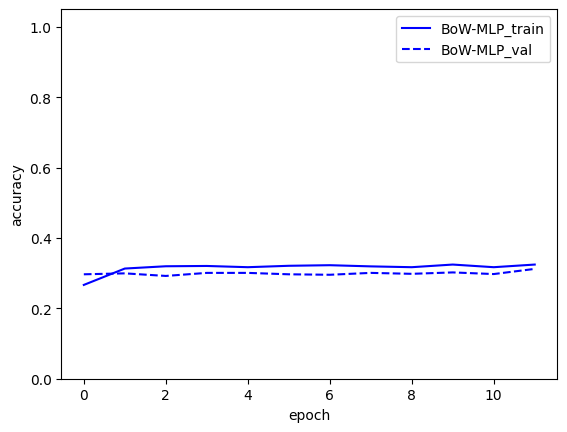

val accuracy: 0.312


In [11]:
class BagOfWordsMLP(nn.Module):
    def __init__(self, vocab=VOCAB, d_model=64, n_class=N_CLASS):
        super().__init__()
        self.embed = nn.Embedding(vocab, d_model)
        self.mlp = nn.Sequential(nn.Linear(d_model, 128), nn.ReLU(),
                                 nn.Linear(128, n_class))
    def forward(self, x):
        h = self.embed(x)          # (N, L, d)
        h = h.mean(dim=1)          # average over positions  -> (N, d)   [order is lost here]
        return self.mlp(h)         # (N, n_class)

bow = BagOfWordsMLP()
print(bow); print('Trainable parameters:', n_params(bow))
m_histories['BoW-MLP'] = train_and_track(bow, epochs=12)
plotter(m_histories, metric='accuracy', ylim=[0.0, 1.05])
print('val accuracy:', round(evaluate(bow, val_loader)[1], 3))

**What is your judgment of this model?**

Accuracy sticks near chance (there are 10 classes, so ~0.1, a little higher because of incidental token-frequency cues). The averaging step throws away *position*, so the model has no way to tell which token followed the marker. **This is exactly the gap self-attention + positional encoding will fill.**

# Building a Transformer encoder, piece by piece

## 1. Positional encoding

Self-attention treats its input as a **set**, permute the tokens and the outputs just permute too. So we must inject position. We use the fixed **sinusoidal** encoding from the slides and *add* it to the token embeddings:

$$PE_{(t,\,2i)} = \sin\!\left(\frac{t}{10000^{2i/d}}\right), \qquad PE_{(t,\,2i+1)} = \cos\!\left(\frac{t}{10000^{2i/d}}\right).$$

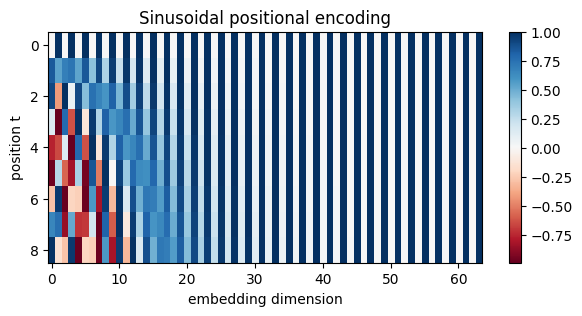

each row is the code added to the token at that position; shape = (9, 64)


In [12]:
def sinusoidal_encoding(length, d_model):
    pos = torch.arange(length).unsqueeze(1)                      # (L, 1)
    idx = torch.arange(d_model).unsqueeze(0)                     # (1, d)
    angle = pos / (10000 ** ((2 * (idx // 2)) / d_model))        # (L, d)
    pe = torch.zeros(length, d_model)
    pe[:, 0::2] = torch.sin(angle[:, 0::2])                      # even dims -> sin
    pe[:, 1::2] = torch.cos(angle[:, 1::2])                      # odd  dims -> cos
    return pe

pe = sinusoidal_encoding(length=9, d_model=64)
plt.figure(figsize=(7, 3))
plt.imshow(pe.numpy(), aspect='auto', cmap='RdBu')
plt.xlabel('embedding dimension'); plt.ylabel('position t'); plt.title('Sinusoidal positional encoding')
plt.colorbar(); plt.show()
print('each row is the code added to the token at that position; shape =', tuple(pe.shape))

## 2. Scaled dot-product attention (the core)

This is the heart of the Transformer, straight from the slide:

$$\mathrm{Attention}(Q,K,V) = \mathrm{softmax}\!\left(\frac{QK^{\top}}{\sqrt{d_k}}\right)V.$$

Every query is compared to every key by a dot product; the scores are scaled by $\sqrt{d_k}$, turned into weights by a row-wise softmax, and used to take a weighted average of the values. We also return the attention weights so we can look at them later.

In [13]:
def scaled_dot_product_attention(Q, K, V, mask=None):
    # Q,K,V: (..., seq, d_k)
    d_k = Q.size(-1)
    scores = Q @ K.transpose(-2, -1) / d_k ** 0.5      # (..., seq_q, seq_k)
    if mask is not None:
        scores = scores.masked_fill(mask == 0, float('-inf'))
    weights = F.softmax(scores, dim=-1)                # rows sum to 1
    output  = weights @ V                              # (..., seq_q, d_k)
    return output, weights

A tiny worked example: 3 tokens, where token 0's query is deliberately aligned with token 2's key. Watch where the attention goes.

In [14]:
torch.manual_seed(0)
q = torch.tensor([[0., 2.], [1., 0.], [0., 0.]])   # query of token 0 points along dim-1
k = torch.tensor([[1., 0.], [0., 1.], [0., 2.]])   # key of token 2 also points along dim-1
v = torch.tensor([[10., 0.], [20., 0.], [30., 0.]])
_, w = scaled_dot_product_attention(q, k, v)
print('attention weights (each row sums to 1):')
print(np.round(w.numpy(), 2))
print('-> token 0 attends most to token', int(w[0].argmax()), '(as designed)')

attention weights (each row sums to 1):
[[0.05 0.19 0.77]
 [0.5  0.25 0.25]
 [0.33 0.33 0.33]]
-> token 0 attends most to token 2 (as designed)


## 3. Multi-head attention

One attention pattern is limiting. **Multi-head** attention runs `h` attentions in parallel, each in its own subspace ($d_k = d/h$), then concatenates and mixes them with an output projection $W_O$. Each head has its own $W_Q, W_K, W_V$.

In [15]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        assert d_model % n_heads == 0
        self.n_heads = n_heads
        self.d_k = d_model // n_heads
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)

    def _split(self, x):                       # (N, L, d) -> (N, h, L, d_k)
        N, L, _ = x.shape
        return x.view(N, L, self.n_heads, self.d_k).transpose(1, 2)

    def forward(self, x):
        Q, K, V = self._split(self.W_q(x)), self._split(self.W_k(x)), self._split(self.W_v(x))
        out, attn = scaled_dot_product_attention(Q, K, V)   # (N, h, L, d_k), (N, h, L, L)
        N, h, L, d_k = out.shape
        out = out.transpose(1, 2).contiguous().view(N, L, h * d_k)   # concat heads
        return self.W_o(out), attn

## 4. The encoder block

One block wraps attention and a position-wise feed-forward network, each inside a **residual connection + LayerNorm** — exactly the diagram on the slides.

In [16]:
class EncoderBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff):
        super().__init__()
        self.mha  = MultiHeadAttention(d_model, n_heads)
        self.ff   = nn.Sequential(nn.Linear(d_model, d_ff), nn.ReLU(),
                                  nn.Linear(d_ff, d_model))
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, x):
        a, attn = self.mha(x)
        x = self.norm1(x + a)          # Add & Norm  (attention sub-layer)
        x = self.norm2(x + self.ff(x)) # Add & Norm  (feed-forward sub-layer)
        return x, attn

## 5. Putting it together — a `[CLS]` classifier

Embed the tokens, add positional encodings, pass through `N` encoder blocks, and classify from the **`[CLS]`** position (index 0) — the sequence-classification recipe from the slides. We keep the attention weights from every layer so we can inspect them.

In [17]:
class TransformerClassifier(nn.Module):
    def __init__(self, vocab=VOCAB, d_model=64, n_heads=4, d_ff=128,
                 n_layers=2, n_class=N_CLASS, max_len=SEQ_LEN + 1):
        super().__init__()
        self.embed = nn.Embedding(vocab, d_model)
        self.register_buffer('pos', sinusoidal_encoding(max_len, d_model))
        self.blocks = nn.ModuleList([EncoderBlock(d_model, n_heads, d_ff)
                                     for _ in range(n_layers)])
        self.head = nn.Linear(d_model, n_class)
        self.last_attn = None                        # cache for visualisation

    def forward(self, x):
        h = self.embed(x) + self.pos[:x.size(1)]     # (N, L, d)
        attns = []
        for blk in self.blocks:
            h, a = blk(h)
            attns.append(a)
        self.last_attn = attns                       # list of (N, h, L, L)
        return self.head(h[:, 0])                    # classify from [CLS] -> (N, n_class)

model = TransformerClassifier()
print(model)
print('Trainable parameters:', n_params(model))

TransformerClassifier(
  (embed): Embedding(12, 64)
  (blocks): ModuleList(
    (0-1): 2 x EncoderBlock(
      (mha): MultiHeadAttention(
        (W_q): Linear(in_features=64, out_features=64, bias=True)
        (W_k): Linear(in_features=64, out_features=64, bias=True)
        (W_v): Linear(in_features=64, out_features=64, bias=True)
        (W_o): Linear(in_features=64, out_features=64, bias=True)
      )
      (ff): Sequential(
        (0): Linear(in_features=64, out_features=128, bias=True)
        (1): ReLU()
        (2): Linear(in_features=128, out_features=64, bias=True)
      )
      (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
    )
  )
  (head): Linear(in_features=64, out_features=10, bias=True)
)
Trainable parameters: 68362


epoch  0  loss 2.003 acc 0.247 | val_loss 1.774 val_acc 0.289
epoch  1  loss 1.693 acc 0.318 | val_loss 1.706 val_acc 0.308
epoch  2  loss 1.627 acc 0.327 | val_loss 1.645 val_acc 0.323
epoch  3  loss 1.466 acc 0.405 | val_loss 1.233 val_acc 0.524
epoch  4  loss 0.605 acc 0.776 | val_loss 0.084 val_acc 0.991
epoch  5  loss 0.051 acc 0.991 | val_loss 0.016 val_acc 1.000
epoch  6  loss 0.012 acc 1.000 | val_loss 0.009 val_acc 1.000
epoch  7  loss 0.008 acc 1.000 | val_loss 0.007 val_acc 1.000
epoch  8  loss 0.006 acc 1.000 | val_loss 0.006 val_acc 1.000
epoch  9  loss 0.005 acc 1.000 | val_loss 0.005 val_acc 1.000
epoch 10  loss 0.004 acc 1.000 | val_loss 0.004 val_acc 1.000
epoch 11  loss 0.004 acc 1.000 | val_loss 0.003 val_acc 1.000
epoch 12  loss 0.003 acc 1.000 | val_loss 0.003 val_acc 1.000
epoch 13  loss 0.003 acc 1.000 | val_loss 0.003 val_acc 1.000
epoch 14  loss 0.002 acc 1.000 | val_loss 0.002 val_acc 1.000


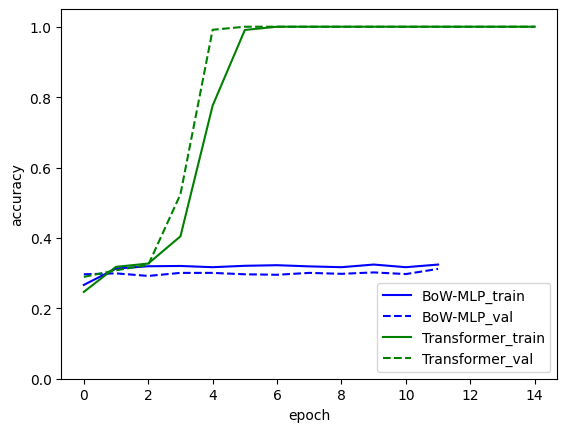

val accuracy: 1.0


In [18]:
m_histories['Transformer'] = train_and_track(model, epochs=15, verbose=True)
plotter(m_histories, metric='accuracy', ylim=[0.0, 1.05])
print('val accuracy:', round(evaluate(model, val_loader)[1], 3))

**What is your judgment of this model?**

It solves the task (validation accuracy → ~1.0), while the Bag-of-Words model could not. The *only* new ingredients are positional encoding and self-attention. Now the interesting part, let us open it up and check *how* it does it.

# Looking inside the model

## Parameter shapes

Notice the per-block `W_q / W_k / W_v / W_o` projections. The only learned parameters of the attention mechanism itself.

In [19]:
for name, p in model.named_parameters():
    if 'blocks.0' in name or name.startswith('embed') or name.startswith('head'):
        print(f'{name:28s} {tuple(p.shape)}')

embed.weight                 (12, 64)
blocks.0.mha.W_q.weight      (64, 64)
blocks.0.mha.W_q.bias        (64,)
blocks.0.mha.W_k.weight      (64, 64)
blocks.0.mha.W_k.bias        (64,)
blocks.0.mha.W_v.weight      (64, 64)
blocks.0.mha.W_v.bias        (64,)
blocks.0.mha.W_o.weight      (64, 64)
blocks.0.mha.W_o.bias        (64,)
blocks.0.ff.0.weight         (128, 64)
blocks.0.ff.0.bias           (128,)
blocks.0.ff.2.weight         (64, 128)
blocks.0.ff.2.bias           (64,)
blocks.0.norm1.weight        (64,)
blocks.0.norm1.bias          (64,)
blocks.0.norm2.weight        (64,)
blocks.0.norm2.bias          (64,)
head.weight                  (10, 64)
head.bias                    (10,)


## Visualising attention. Does `[CLS]` look at the right place?

For a few test sequences we plot the **last layer's** attention weights *from the `[CLS]` slot* to every position (averaged over heads). If our story is right, the biggest weight should sit on the position **immediately after the marker**.

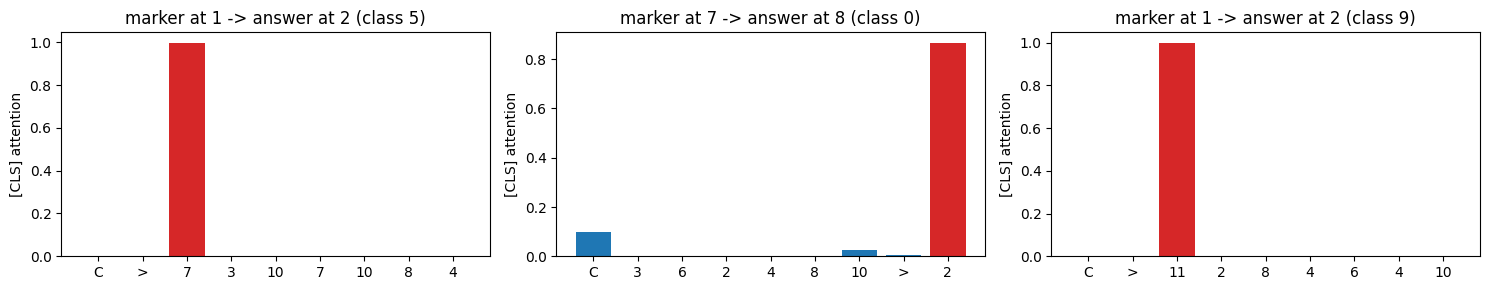

The red bar (token after the marker) receives almost all of the [CLS] attention.


In [20]:
model.eval()
xb = torch.from_numpy(X_test[:3]).to(device)
with torch.no_grad():
    _ = model(xb)
attn_last = model.last_attn[-1]            # (N, h, L, L)  last layer
cls_attn  = attn_last.mean(1)[:, 0, :]     # avg heads, take [CLS] row -> (N, L)

fig, axes = plt.subplots(1, 3, figsize=(15, 3))
for i, ax in enumerate(axes):
    x = X_test[i]
    marker_pos = int(np.where(x == MARKER)[0][0])
    ans_pos = marker_pos + 1
    ax.bar(range(len(x)), cls_attn[i].cpu().numpy(),
           color=['tab:red' if j == ans_pos else 'tab:blue' for j in range(len(x))])
    labels = ['C'] + ['>' if t == MARKER else str(t) for t in x[1:]]
    ax.set_xticks(range(len(x))); ax.set_xticklabels(labels)
    ax.set_title(f'marker at {marker_pos} -> answer at {ans_pos} (class {y_test[i]})')
    ax.set_ylabel('[CLS] attention')
plt.tight_layout(); plt.show()
print('The red bar (token after the marker) receives almost all of the [CLS] attention.')

We can also see the whole picture: the full attention matrix of the last layer for one example. Row = who is attending, column = who is attended to.

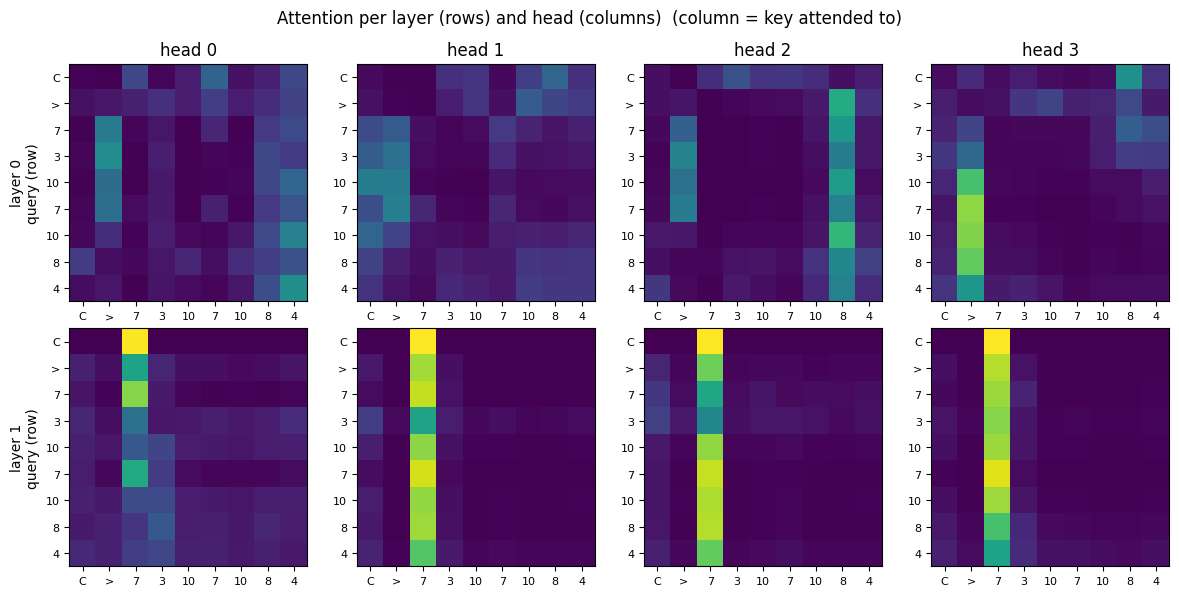

In [24]:
ex = 0
x = X_test[ex]
labels = ['C'] + ['>' if t == MARKER else str(t) for t in x[1:]]

all_attn = model.last_attn                 # list of (N, h, L, L), one per layer
n_layers = len(all_attn)
n_heads  = all_attn[0].size(1)

fig, axes = plt.subplots(n_layers, n_heads,
                         figsize=(3 * n_heads, 3 * n_layers),
                         squeeze=False)     # always 2D, even with 1 layer/head
for li in range(n_layers):
    for hd in range(n_heads):
        ax = axes[li, hd]
        ax.imshow(all_attn[li][ex, hd].cpu().numpy(), cmap='viridis', vmin=0, vmax=1)
        ax.set_xticks(range(len(x))); ax.set_xticklabels(labels, fontsize=8)
        ax.set_yticks(range(len(x))); ax.set_yticklabels(labels, fontsize=8)
        if li == 0:
            ax.set_title(f'head {hd}')
        if hd == 0:
            ax.set_ylabel(f'layer {li}\nquery (row)')
plt.suptitle('Attention per layer (rows) and head (columns)  (column = key attended to)')
plt.tight_layout(); plt.show()

**Reading the maps.** Different heads specialise, and the `[CLS]` row (top) concentrates on the post-marker position. With two layers the model composes the lookup: an early layer lets each token notice whether it *follows* the marker, and the final layer lets `[CLS]` copy from that flagged position. We never told it to do this, it emerged from training on the task.

## Positional encoding, revisited

A quick sanity check that positions are distinguishable: the dot product between the positional code at position 4 and every other position is largest at 4 and decays with distance, so "nearby" is encoded.

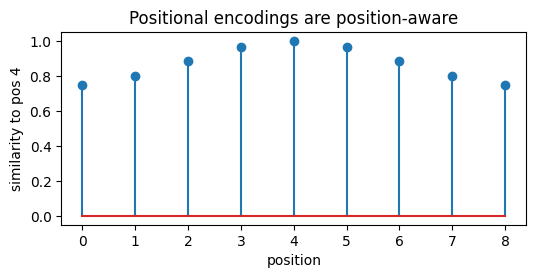

In [22]:
pe = sinusoidal_encoding(9, 64)
pe = pe / pe.norm(dim=1, keepdim=True)
sims = (pe @ pe[4]).numpy()
plt.figure(figsize=(6, 2.5))
plt.stem(range(9), sims)
plt.xlabel('position'); plt.ylabel('similarity to pos 4'); plt.title('Positional encodings are position-aware')
plt.show()

# Final evaluation on the test set

> 🚨 **Course policy:** the test set is touched **once**, at the very end — never for tuning.

In [23]:
model.eval()
with torch.no_grad():
    logits = model(torch.from_numpy(X_test).to(device))
    pred = logits.argmax(1).cpu().numpy()
print(classification_report(y_test, pred, digits=3))

              precision    recall  f1-score   support

           0      1.000     1.000     1.000       210
           1      1.000     1.000     1.000       206
           2      1.000     1.000     1.000       201
           3      1.000     1.000     1.000       204
           4      1.000     1.000     1.000       204
           5      1.000     1.000     1.000       195
           6      1.000     1.000     1.000       199
           7      1.000     1.000     1.000       194
           8      1.000     1.000     1.000       189
           9      1.000     1.000     1.000       198

    accuracy                          1.000      2000
   macro avg      1.000     1.000     1.000      2000
weighted avg      1.000     1.000     1.000      2000



# Wrap-up

Starting from integer tokens we built: **positional encoding**, **scaled dot-product attention**, **multi-head attention**, the **encoder block**, and **`[CLS]` classification**. The payoff was not accuracy but *interpretability*: the attention map shows the model looking exactly where we expected.

**Things to try as exercises**
* Set `n_layers=1` — can a single layer still solve the marker-lookup task? Why or why not?
* Remove the positional encoding (`+ self.pos`) — what happens, and what does that tell you?
* Add a **causal mask** to `scaled_dot_product_attention` (upper-triangular `-inf`) and turn this into a next-token *generator* instead of a classifier.
* Increase `n_heads` and inspect whether different heads specialise.

**Note.** For real work you would use the built-in `nn.MultiheadAttention` / `nn.TransformerEncoderLayer`, which do exactly what we implemented here (plus dropout and performance tricks). We built it by hand only to see the moving parts.